<a href="https://colab.research.google.com/github/oktvindh/Praktikum-Machine-Learning/blob/main/praktikumBAB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, validation_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [2]:
data = pd.read_csv("breast-cancer.csv")
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print("Ukuran data:", X.shape)
print("Distribusi kelas:", np.bincount(y))


Ukuran data: (569, 30)
Distribusi kelas: [212 357]


In [ ]:
data.frame.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [5]:
data.frame.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [ ]:
data.frame.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [6]:
X_train,X_test,y_train,y_test = train_test_split( X,y,
test_size=0.2,random_state=42,stratify=y )

In [7]:
# Model tanpa pruning (tumbuh penuh)
tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_train, y_train)
# Model dengan pre-pruning
tree_pruned = DecisionTreeClassifier(max_depth=4,
min_samples_leaf=5,random_state=42)
tree_pruned.fit(X_train, y_train)
# Model dengan post-pruning (Cost Complexity Pruning)
path = tree_full.cost_complexity_pruning_path(X_train,
y_train)
ccp_alpha_terpilih = path.ccp_alphas[len(path.ccp_alphas)//
2] # contoh pemilihan alpha
tree_ccp = DecisionTreeClassifier(ccp_alpha=ccp_alpha_terpilih,
random_state=42)
tree_ccp.fit(X_train, y_train)

DecisionTreeClassifier(ccp_alpha=np.float64(0.005274725274725275),
                       random_state=42)

In [8]:
for nama,model in [("Tanpa Pruning",tree_full),
    ("Pre-Pruning",tree_pruned),("Post-Pruning (CCP)",
    tree_ccp)]:
    acc_train = accuracy_score(y_train,
    model.predict(X_train))
    acc_test = accuracy_score(y_test,model.predict(X_test))
    print(f"{nama}: Akurasi Train={acc_train:.3f}, Akurasi Test={acc_test:.3f}, Gap={acc_train-acc_test:.3f}")

Tanpa Pruning: Akurasi Train=1.000, Akurasi Test=0.912, Gap=0.088
Pre-Pruning: Akurasi Train=0.976, Akurasi Test=0.921, Gap=0.055
Post-Pruning (CCP): Akurasi Train=0.978, Akurasi Test=0.930, Gap=0.048


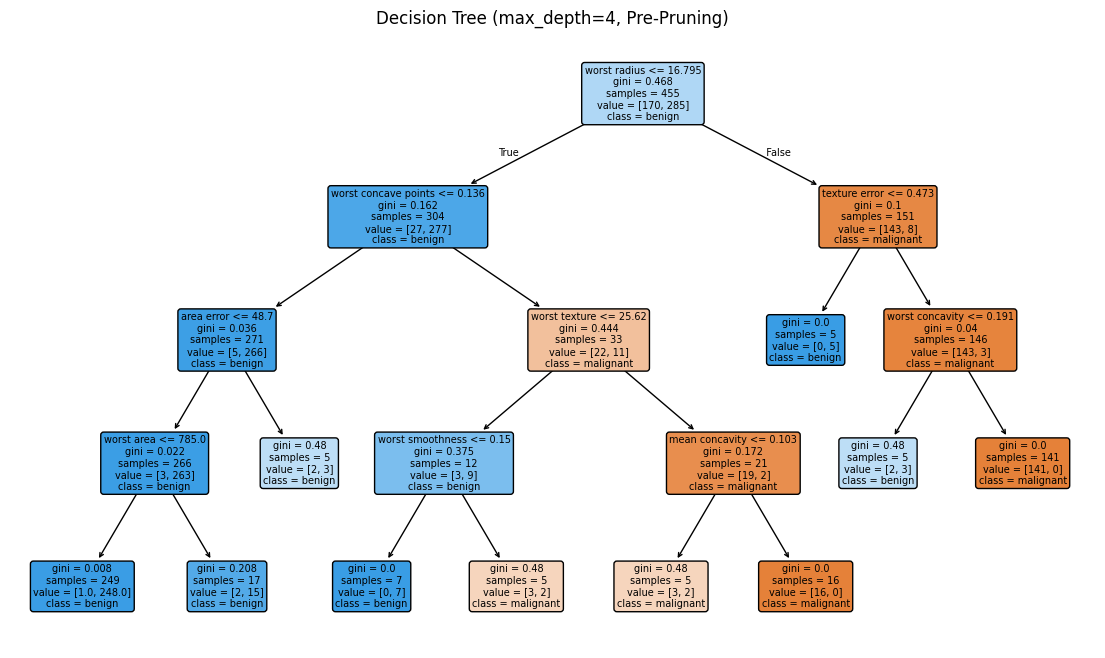

In [9]:
plt.figure(figsize=(14,8))
plot_tree(tree_pruned,feature_names=data.feature_names,
class_names=data.target_names,filled=True,rounded=True,
fontsize=7)
plt.title("Decision Tree (max_depth=4, Pre-Pruning)")
plt.show()

## Latihan Praktikum

### Praktikum 1: Eksperimen Parameter Pre-Pruning
Tujuan: Mahasiswa mampu mengamati pengaruh kombinasi parameter pre-pruning
terhadap performa model.

In [11]:
for depth in [2, 4, 6, None]:
    for min_leaf in [1, 5, 10]:
        model = DecisionTreeClassifier(max_depth=depth,
            min_samples_leaf=min_leaf,random_state=42)
        model.fit(X_train, y_train)
        acc = accuracy_score(y_test, model.predict(X_test))
        print(f"max_depth={depth}, min_samples_leaf={min_leaf}: akurasi test={acc:.3f}")

max_depth=2, min_samples_leaf=1: akurasi test=0.895
max_depth=2, min_samples_leaf=5: akurasi test=0.895
max_depth=2, min_samples_leaf=10: akurasi test=0.904
max_depth=4, min_samples_leaf=1: akurasi test=0.939
max_depth=4, min_samples_leaf=5: akurasi test=0.921
max_depth=4, min_samples_leaf=10: akurasi test=0.947
max_depth=6, min_samples_leaf=1: akurasi test=0.912
max_depth=6, min_samples_leaf=5: akurasi test=0.930
max_depth=6, min_samples_leaf=10: akurasi test=0.947
max_depth=None, min_samples_leaf=1: akurasi test=0.912
max_depth=None, min_samples_leaf=5: akurasi test=0.930
max_depth=None, min_samples_leaf=10: akurasi test=0.947


### Praktikum 2: Cost Complexity Pruning Path
Tujuan: Mahasiswa mampu memilih ccp_alpha optimal berdasarkan kurva akurasi
terhadap alpha.

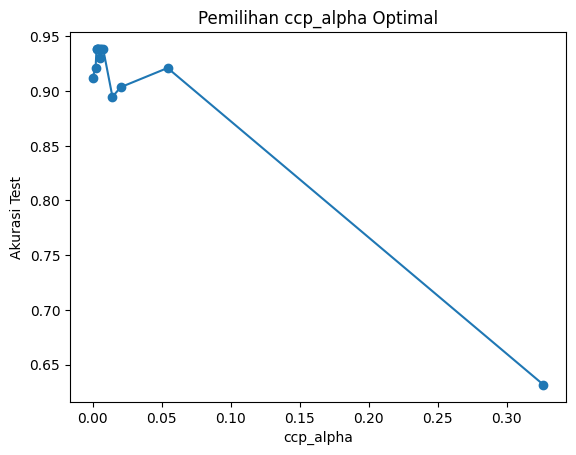

In [13]:
path = tree_full.cost_complexity_pruning_path(X_train,
    y_train)
akurasi_test = []
for alpha in path.ccp_alphas:
    m = DecisionTreeClassifier(ccp_alpha=alpha,
        random_state=42).fit(X_train,y_train)
    akurasi_test.append(accuracy_score(y_test,
        m.predict(X_test)))

plt.plot(path.ccp_alphas, akurasi_test, marker='o')
plt.xlabel("ccp_alpha"); plt.ylabel("Akurasi Test")
plt.title("Pemilihan ccp_alpha Optimal")
plt.show()

In [14]:
# Tentukan ccp_alpha dengan akurasi test tertinggi, lalu bandingkan jumlah leaf node-nya
# Tentukan ccp_alpha dengan akurasi test tertinggi
best_alpha_idx = np.argmax(akurasi_test)
best_alpha = path.ccp_alphas[best_alpha_idx]
print(
    f"ccp_alpha optimal: {best_alpha:.5f} dengan akurasi test:"
    f" {akurasi_test[best_alpha_idx]:.3f}"
)

# Melatih ulang model menggunakan ccp_alpha optimal
best_ccp_model = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=42)
best_ccp_model.fit(X_train, y_train)

# Membandingkan jumlah leaf node
print(f"Jumlah leaf node (Tanpa Pruning): {tree_full.get_n_leaves()}")
print(f"Jumlah leaf node (Post-Pruning Optimal): {best_ccp_model.get_n_leaves()}")

ccp_alpha optimal: 0.00287 dengan akurasi test: 0.939
Jumlah leaf node (Tanpa Pruning): 19
Jumlah leaf node (Post-Pruning Optimal): 12


np.argmax(akurasi_test): Digunakan untuk mencari indeks dari nilai akurasi test maksimum di dalam daftar akurasi_test.

best_alpha: Nilai complexity parameter ($\alpha$) terpilih yang memberikan performa generalisasi terbaik pada data test.

get_n_leaves(): Fungsi untuk menghitung jumlah leaf node pada pohon keputusan. Biasanya, model hasil post-pruning akan memiliki jumlah leaf node yang jauh lebih sedikit (lebih sederhana dan tidak overfitting) dibanding model yang tumbuh penuh tanpa pruning.